# Week 4 — Preprocessing & Feature Engineering
## Hands-on challenge: from messy data to model-ready data

You are given a synthetic survey dataset. Your goal is **not** a perfect dataset; it is a set of **defensible preprocessing decisions**.

We follow the same workflow as the lecture:

| Step | What | Before or after the split? |
|---|---|---|
| 1 | Inspect | before (read-only) |
| 2 | Remove duplicates, fix labels, flag impossible values | before — row-wise rules, nothing is learned |
| 3 | Choose target and features, check for target leakage | before |
| 4 | **Train / test split** | — |
| 5 | Missing values | after — medians/modes are learned from **train** |
| 6 | Outliers | after — investigate on **train** |
| 7 | Dates | after (row-wise, applied to both) |
| 8 | Engineer new features | after (row-wise, applied to both) |
| 9 | Encode categories | after — categories are learned from **train** |
| 10 | Scale numerical variables | after — mean/SD learned from **train** |
| 11 | Build a preprocessing pipeline | — |
| 12 | Leakage, revisited | — |

**Rule of thumb:** anything that *learns* from the data goes after the split; pure row-wise corrections can come before.

Run each worked example, inspect its output, and answer the short questions.

In [44]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer

candidate_paths = [
    Path("../data/week4_messy_survey.csv"),
    Path("../data/sample_messy_survey.csv"),
    Path("data/week4_messy_survey.csv"),
    Path("data/sample_messy_survey.csv"),
]

csv_path = next((p for p in candidate_paths if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError(
        "No survey CSV was found. Expected one of: "
        + ", ".join(str(p) for p in candidate_paths)
    )

df = pd.read_csv(csv_path)
print(f"Loaded dataset from: {csv_path}")
df.head()


Loaded dataset from: ../data/week4_messy_survey.csv


,respondent_id,gender,age,education,household_size,annual_income_eur,hours_online_per_week,online_purchases_last_month,survey_date,complaint_filed_after_survey,satisfaction_score
0,1,f,68,High School,5,144929,4,7,2025-05-20,0,4
1,2,male,63,High School,1,128152,32,21,2025-01-24,0,5
2,3,Male,52,MASTER,5,168929,16,0,2025-12-29,1,4
3,4,Male,130,Bachelor,1,173772,11,11,2025-07-17,0,3
4,5,Female,25,Bachelor,1,-2500,2,20,2024-01-13,0,3


---
## 1. Inspect the dataset

Before changing anything, find out what you have. Inspecting the full dataset is fine — you are only *looking*, not learning parameters.

**Observe**
- How many rows and columns? What are the data types?
505 rows and 11 columns, 8 integer columns and 3 string columns
- Which columns contain missing values, and how many?
gener: 3 and education: 20
- Are there duplicate rows?
yes 5 
- What do `describe()` and `value_counts()` tell you? **Read the min and max first.
first and last values **

In [45]:
# Shape and data types
# Hint: df.shape, df.info()
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   respondent_id                 505 non-null    int64 
 1   gender                        502 non-null    object
 2   age                           505 non-null    int64 
 3   education                     485 non-null    object
 4   household_size                505 non-null    int64 
 5   annual_income_eur             505 non-null    int64 
 6   hours_online_per_week         505 non-null    int64 
 7   online_purchases_last_month   505 non-null    int64 
 8   survey_date                   505 non-null    object
 9   complaint_filed_after_survey  505 non-null    int64 
 10  satisfaction_score            505 non-null    int64 
dtypes: int64(8), object(3)
memory usage: 43.5+ KB


In [46]:
# Missing values, duplicates, summary statistics
# Hint: df.isna().sum(), df.duplicated().sum(), df.describe()
df.isna().sum()
df.duplicated().sum()
df.describe()

,respondent_id,age,household_size,annual_income_eur,hours_online_per_week,online_purchases_last_month,complaint_filed_after_survey,satisfaction_score
count,505.000000,505.000000,505.000000,505.000000,505.000000,505.000000,505.000000,505.000000
mean,248.029703,49.293069,3.592079,101627.150495,25.251485,11.398020,0.099010,2.849505
std,145.874447,18.319293,1.733178,44879.582149,14.002059,7.159326,0.298971,1.425785
min,1.000000,18.000000,1.000000,-2500.000000,2.000000,0.000000,0.000000,1.000000
25%,122.000000,35.000000,2.000000,60982.000000,12.000000,6.000000,0.000000,2.000000
50%,248.000000,49.000000,4.000000,99396.000000,26.000000,11.000000,0.000000,3.000000
75%,374.000000,65.000000,5.000000,142578.000000,37.000000,18.000000,0.000000,4.000000
max,500.000000,130.000000,6.000000,179876.000000,49.000000,24.000000,1.000000,5.000000


In [47]:
# Categorical counts — include missing values
# Hint: df[col].value_counts(dropna=False)
df["gender"].value_counts(dropna=False)


gender
Female               241
Male                 238
Non-binary            13
f                      6
NaN                    3
Prefer not to say      3
male                   1
Name: count, dtype: int64

---
## 2. Row-wise cleaning (before the split)

These steps are **rules you decide**, not statistics learned from the data. That is why they can happen before the split.

**Tasks**
1. Remove exact duplicate rows. *Why before the split?* Otherwise a copy of the same person can land in both train and test.
2. Standardise the labels in `gender` and `education` (`"F"`, `"female"`, `" Male"`, `"MASTER"`, …).
3. Replace **impossible** values with `NaN`: which ages and incomes are impossible, not just unusual?

**Think first:** which problems can be fixed automatically, and which require a decision?

In [48]:
df_clean = df.copy().drop_duplicates()

# Standardise categorical labels with fixed, row-wise rules.
gender_map = {
    "f": "Female", "female": "Female", "m": "Male", "male": "Male",
    "non-binary": "Non-binary", "prefer not to say": "Prefer not to say",
}
education_map = {
    "high school": "High School", "bachelor": "Bachelor",
    "master": "Master", "phd": "PhD",
}

df_clean["gender"] = (
    df_clean["gender"].str.strip().str.lower().map(gender_map)
)
df_clean["education"] = (
    df_clean["education"].str.strip().str.lower().map(education_map)
)

# These values are fairly impossible rather than merely unusual. 
df_clean.loc[df_clean["age"] > 110, "age"] = np.nan
df_clean.loc[df_clean["annual_income_eur"] < 0, "annual_income_eur"] = np.nan

print("Rows after removing duplicates:", len(df_clean))
print("\nStandardised gender labels:")
print(df_clean["gender"].value_counts(dropna=False))

Rows after removing duplicates: 500

Standardised gender labels:
gender
Female               242
Male                 239
Non-binary            13
NaN                    3
Prefer not to say      3
Name: count, dtype: int64


**Checkpoint.** Run this cell. If an assertion fails, go back and fix section 2.

In [49]:
assert df_clean.duplicated().sum() == 0, "There are still duplicate rows"
assert set(df_clean["gender"].dropna()) <= {"Female", "Male", "Non-binary", "Prefer not to say"}, "Gender labels not standardised"
assert set(df_clean["education"].dropna()) == {"High School", "Bachelor", "Master", "PhD"}, "Education labels not standardised"
assert df_clean["age"].max() <= 110, "Impossible ages remain"
assert (df_clean["annual_income_eur"].dropna() >= 0).all(), "Negative incomes remain"
print("Section 2 checks passed:", df_clean.shape)

Section 2 checks passed: (500, 11)


---
## 3. Target and features — check for target leakage

We want to predict `satisfaction_score`.

**Think:** for every column, ask *would this be available **before** we know the satisfaction score?*

- Which column only exists **because of** the outcome? That is **target leakage**: remove that column.

- Which column carries no information at all and should not be a feature?
exclude respondent_id has no meaningful predictive information

In [50]:
target = "satisfaction_score"

# A respondent ID is only an identifier. A complaint filed after the survey
# is known too late to use when predicting satisfaction at survey time.
leaky_cols = ["complaint_filed_after_survey"]
id_cols = ["respondent_id"]

X = df_clean.drop(columns=[target] + leaky_cols + id_cols)
y = df_clean[target]
print("Features used:", X.columns.tolist())

Features used: ['gender', 'age', 'education', 'household_size', 'annual_income_eur', 'hours_online_per_week', 'online_purchases_last_month', 'survey_date']


---
## 4. Train / test split

From here on, **anything that learns from the data is fitted on `X_train` only** and then applied to `X_test`.

The test set is looked at **once, at the end**.

In [51]:
# Keep 20% of the rows aside. random_state makes this split reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("train:", X_train.shape, " test:", X_test.shape)

# Sections 5-10 change Xtr/Xte. These copies keep X_train/X_test untouched
# for the all-in-one pipeline in section 11.
Xtr, Xte = X_train.copy(), X_test.copy()

train: (400, 8)  test: (100, 8)


---
## 5. Missing values

Missing ≠ zero ≠ unknown ≠ not applicable.

**Observe:** how much is missing in each column of `Xtr`? Some of these `NaN`s are values you created in section 2.
Xtr has 18 missing education values, 2 gender values, 1 age and then 1 income
**Think:** for each column, which option fits — median, mean, most frequent, an `"Unknown"` category, or dropping rows?
- Why is the median usually safer than the mean for income?
median is less affected by extreme incomes than the mean
- Why might `"Unknown"` be fine for `gender` but awkward for `education` (an ordinal variable)? unknown works as a distinct gender category but education has an order and unknown does not fit into that order. 
**Code:** compute the fill values **from `Xtr`**, then apply the *same* values to both `Xtr` and `Xte`.

In [52]:
# These are the columns where a median can be appropriate.
numeric_cols = [
    "age", "household_size", "annual_income_eur", "hours_online_per_week",
    "online_purchases_last_month",
]

print("Missing values in the training data:")
print(Xtr.isna().sum().sort_values(ascending=False))

# Learn one median per numeric column from TRAINING data only.
# The test set must not influence this choice.
medians = Xtr[numeric_cols].median()

# Reuse the training medians in both datasets.
Xtr[numeric_cols] = Xtr[numeric_cols].fillna(medians)
Xte[numeric_cols] = Xte[numeric_cols].fillna(medians)

# "Unknown" is a meaningful extra category for a nominal variable such as gender.
Xtr["gender"] = Xtr["gender"].fillna("Unknown")
Xte["gender"] = Xte["gender"].fillna("Unknown")

# Education is ordinal, so we use the most common TRAINING value instead.
education_mode = Xtr["education"].mode()[0]
Xtr["education"] = Xtr["education"].fillna(education_mode)
Xte["education"] = Xte["education"].fillna(education_mode)

print("\nMissing values after imputation:")
print(Xtr.isna().sum().sum(), "in train;", Xte.isna().sum().sum(), "in test")

Missing values in the training data:
education                      18
gender                          2
age                             1
annual_income_eur               1
household_size                  0
hours_online_per_week           0
online_purchases_last_month     0
survey_date                     0
dtype: int64

Missing values after imputation:
0 in train; 0 in test


---
## 6. Outliers and suspicious values

The *impossible* values were handled in section 2. What is left may be **unusual but real**.

**Observe:** use descriptive statistics and at least one plot to investigate `age` and `annual_income_eur` in `Xtr`. 

**Think:** is an unusual value necessarily an error? Would you remove an income of €480,000? What would removing it do to the model — and to the people it describes? an unsusual value isnt automatically an error, removing a high income could distort the data and underrepressent people with h9igh incomes. 

              age  annual_income_eur
count  400.000000         400.000000
mean    49.007500      102731.407500
std     18.255701       44418.594718
min     18.000000       22497.000000
25%     34.000000       62376.750000
50%     49.000000      101454.000000
75%     65.000000      142709.500000
max     79.000000      179876.000000

Five largest incomes:
206    179876.0
121    179815.0
157    179182.0
174    179139.0
237    179064.0
Name: annual_income_eur, dtype: float64


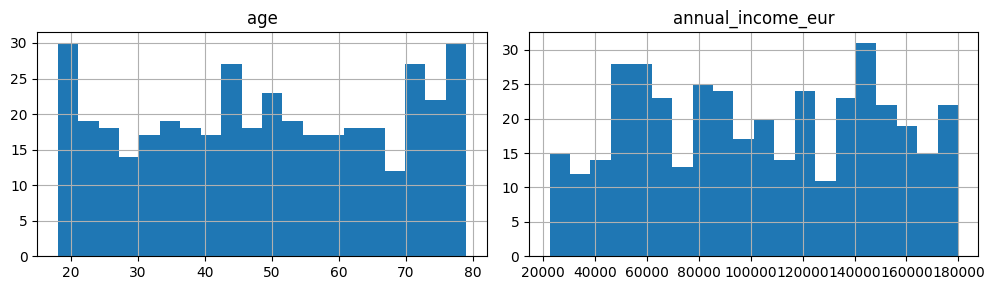

In [53]:
print(Xtr[["age", "annual_income_eur"]].describe())
print("\nFive largest incomes:")
print(Xtr["annual_income_eur"].nlargest(5))

Xtr[["age", "annual_income_eur"]].hist(bins=20, figsize=(10, 3))
plt.tight_layout()
plt.show()

# Minimal question: Based on the output, should the largest income be kept?
# It is unusual but still plausible, so we keep it.

---
## 7. Dates

`survey_date` is stored as text. Convert it to a datetime and extract at least one useful feature.

**Think:** some dates can't be parsed. What should happen to them? Is this step row-wise (no learning) or not? 

In [54]:
def add_date_features(data):
    # Work on a copy so this function does not modify its input dataframe.
    result = data.copy()

    # Invalid date strings become NaT rather than causing an error.
    dates = pd.to_datetime(result["survey_date"], errors="coerce")

    # A date contains useful calendar information for a later model.
    result["survey_month"] = dates.dt.month
    result["survey_dayofweek"] = dates.dt.dayofweek

    # We have extracted the useful parts, so the original text column is no longer needed.
    return result.drop(columns="survey_date")

# Apply exactly the same row-wise operation to train and test data.
Xtr = add_date_features(Xtr)
Xte = add_date_features(Xte)

# If parsing made a date part missing, learn replacement values from training data.
date_cols = ["survey_month", "survey_dayofweek"]
date_medians = Xtr[date_cols].median()
Xtr[date_cols] = Xtr[date_cols].fillna(date_medians)
Xte[date_cols] = Xte[date_cols].fillna(date_medians)
Xtr[["survey_month", "survey_dayofweek"]].head()

,survey_month,survey_dayofweek
249,9,0
433,8,2
19,11,5
322,10,5
332,10,4


**Answer:** Dates that cannot be parsed become missing values (`NaT`), so the code fills their month and day-of-week values using medians learned from the training set. Extracting the date parts is row-wise because each date is handled independently; calculating the replacement medians is the part that learns from the training data.

---
## 8. Feature engineering

Create **at least two new features** that could plausibly help predict satisfaction. Write one sentence per feature explaining why.

Ideas: income per household member, age group, purchases per online hour.

**Why here, before encoding and scaling?** A ratio of two *scaled* variables is meaningless — engineer features from the original units.

In [55]:
def add_features(data):
    # Work on a copy, so the same function is safe for either split.
    result = data.copy()

    # A household with the same income may have a different situation depending on its size.
    # clip(lower=1) prevents division by zero.
    result["income_per_person"] = (
        result["annual_income_eur"] / result["household_size"].clip(lower=1)
    )

    # clip(lower=0.1) prevents a zero number of online hours from causing an error.
    result["purchases_per_online_hour"] = (
        result["online_purchases_last_month"] / result["hours_online_per_week"].clip(lower=0.1)
    )

    # Age groups are categories, not numeric scores; they will be one-hot encoded later.
    result["age_group"] = pd.cut(
        result["age"], bins=[0, 29, 44, 64, np.inf],
        labels=["18-29", "30-44", "45-64", "65+"],
    ).astype("object")
    return result

# The recipe is fixed, so apply it identically to train and test data.
Xtr = add_features(Xtr)
Xte = add_features(Xte)
Xtr[["income_per_person", "purchases_per_online_hour", "age_group"]].head()

,income_per_person,purchases_per_online_hour,age_group
249,14074.500000,0.200000,65+
433,25074.333333,0.054054,45-64
19,23290.333333,0.369565,18-29
322,146285.000000,0.392857,45-64
332,30604.500000,0.525000,30-44


---
## 9. Encoding categorical variables

**Think:** for `education`, `gender` and `age_group` — nominal or ordinal?

- **Ordinal** → `OrdinalEncoder` with the categories in an **explicit order**. (Don't use `LabelEncoder` — it sorts alphabetically and is meant for targets.)
- **Nominal** → `OneHotEncoder(handle_unknown="ignore")`, so a category that only appears in the test set doesn't crash the model.

Fit the encoders on `Xtr`, transform both.

In [56]:
# This order is meaningful, so education is an ordinal variable.
edu_order = ["High School", "Bachelor", "Master", "PhD"]
education_encoder = OrdinalEncoder(categories=[edu_order])

# fit_transform learns the order from the training configuration and encodes training rows.
Xtr[["education"]] = education_encoder.fit_transform(Xtr[["education"]])

# transform applies exactly the same mapping to the test rows.
Xte[["education"]] = education_encoder.transform(Xte[["education"]])

# Gender and age group have no meaningful numeric order, so create separate 0/1 columns.
nominal_cols = ["gender", "age_group"]
nominal_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# Learn which category columns exist from training data only.
train_nominal = pd.DataFrame(
    nominal_encoder.fit_transform(Xtr[nominal_cols]),
    columns=nominal_encoder.get_feature_names_out(nominal_cols), index=Xtr.index,
)

# An unseen test category is ignored rather than causing an error.
test_nominal = pd.DataFrame(
    nominal_encoder.transform(Xte[nominal_cols]),
    columns=nominal_encoder.get_feature_names_out(nominal_cols), index=Xte.index,
)

# Replace the original text columns with their new numeric columns.
Xtr = pd.concat([Xtr.drop(columns=nominal_cols), train_nominal], axis=1)
Xte = pd.concat([Xte.drop(columns=nominal_cols), test_nominal], axis=1)
print("Columns after encoding:", Xtr.shape[1])

Columns after encoding: 19


---
## 10. Scaling numerical variables

Some columns use very different units. For example, age might be around 20-80, while annual income can be tens of thousands. A later algorithm could treat income as more important simply because its numbers are larger.

**Standardisation** changes each numeric column so that its training values are centred around 0 and use a comparable scale. It does not change which values are relatively high or low within a column.

The code below:

1. compares the original ranges;
2. learns a mean and standard deviation from the training data; and
3. uses those same training values to standardise both the training and test sets.

The one-hot columns already contain only 0 and 1, so we leave them unchanged.

In [57]:
# One-hot columns are already 0/1, so scale only continuous or count-based variables.
numeric_cols = [
    "age", "household_size", "annual_income_eur", "hours_online_per_week",
    "online_purchases_last_month", "survey_month", "survey_dayofweek",
    "income_per_person", "purchases_per_online_hour",
]
print("Ranges before scaling:")
print(Xtr[numeric_cols].agg(["min", "max"]))

# The scaler learns the mean and standard deviation from training data only.
scaler = StandardScaler()
Xtr[numeric_cols] = scaler.fit_transform(Xtr[numeric_cols])

# The test set uses those same training values; it must not calculate new ones.
Xte[numeric_cols] = scaler.transform(Xte[numeric_cols])

print("\nTraining means after scaling:")
print(Xtr[numeric_cols].mean().round(2))

Ranges before scaling:
      age  household_size  annual_income_eur  hours_online_per_week  \
min  18.0               1            22497.0                      2   
max  79.0               6           179876.0                     49   

     online_purchases_last_month  survey_month  survey_dayofweek  \
min                            0             1                 0   
max                           24            12                 6   

     income_per_person  purchases_per_online_hour  
min             4310.5                        0.0  
max           177887.0                       11.5  

Training means after scaling:
age                           -0.0
household_size                 0.0
annual_income_eur             -0.0
hours_online_per_week          0.0
online_purchases_last_month    0.0
survey_month                   0.0
survey_dayofweek               0.0
income_per_person             -0.0
purchases_per_online_hour     -0.0
dtype: float64


**Answer:** The training columns have means close to 0 because the scaler used their own means and standard deviations. The test columns do not need to have means of 0: they use the training values so that the test data stays genuinely unseen.

---
## 11. Doing the same preparation with a pipeline

So far, we have prepared the data one step at a time: fill missing values, extract date information, create new features, encode categories, and scale numeric columns.

A **pipeline** is simply a saved checklist of those steps. Instead of writing and running each step separately every time, we put the steps in the correct order once and ask Python to run that checklist for us.

For this notebook, the pipeline does the following:

1. Starts with the original training or test table.
2. Extracts month and day of week from `survey_date` and creates the two ratio features.
3. Fills missing numeric values, then standardises numeric columns.
4. Fills and encodes `education` in its meaningful order.
5. Fills and turns `gender` and `age_group` into 0/1 columns.

When we run `fit_transform(X_train)`, the pipeline learns any required values, such as medians and category lists, from the training data and prepares it. When we run `transform(X_test)`, it follows the exact same checklist for the test data but reuses the values learned from training.

This keeps our preparation consistent and prevents us from accidentally learning from the test data. It is still only data preparation; we are not building a predictive model yet.

In [58]:
def row_wise_features(data):
    """Create features using each row only; no dataset-wide values are learned here."""
    result = data.copy()

    # Turn one date column into two numeric calendar features.
    dates = pd.to_datetime(result["survey_date"], errors="coerce")
    result["survey_month"] = dates.dt.month
    result["survey_dayofweek"] = dates.dt.dayofweek

    # Create ratios before scaling, while values still use their original units.
    result["income_per_person"] = (
        result["annual_income_eur"] / result["household_size"].clip(lower=1)
    )
    result["purchases_per_online_hour"] = (
        result["online_purchases_last_month"] / result["hours_online_per_week"].clip(lower=0.1)
    )

    # Keep age bands as categories; the nominal pipeline will encode them.
    result["age_group"] = pd.cut(
        result["age"], bins=[0, 29, 44, 64, np.inf],
        labels=["18-29", "30-44", "45-64", "65+"],
    ).astype("object")
    return result.drop(columns="survey_date")

# Assign each column to the type of preprocessing it needs.
numeric_cols = [
    "age", "household_size", "annual_income_eur", "hours_online_per_week",
    "online_purchases_last_month", "survey_month", "survey_dayofweek",
    "income_per_person", "purchases_per_online_hour",
]
ordinal_cols = ["education"]
nominal_cols = ["gender", "age_group"]
edu_order = ["High School", "Bachelor", "Master", "PhD"]

# For numeric data: fill gaps with training medians, then put columns on a common scale.
numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

# For education: fill gaps, then encode the supplied meaningful order.
ordinal_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OrdinalEncoder(categories=[edu_order])),
])

# For nominal data: label missing values and create a 0/1 column for each category.
nominal_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

# Send each group of columns through its appropriate mini-pipeline.
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("ord", ordinal_pipeline, ordinal_cols),
    ("nom", nominal_pipeline, nominal_cols),
])

# First create features, then preprocess the resulting columns.
preprocessing_pipeline = Pipeline([
    ("features", FunctionTransformer(row_wise_features)),
    ("preprocess", preprocessor),
])

# fit_transform learns every required value from the training data and transforms it.
X_train_prepared = preprocessing_pipeline.fit_transform(X_train)

# transform applies those already-learned values to the unseen test data.
X_test_prepared = preprocessing_pipeline.transform(X_test)
print("Prepared train shape:", X_train_prepared.shape)
print("Prepared test shape: ", X_test_prepared.shape)

Prepared train shape: (400, 20)
Prepared test shape:  (100, 20)


### Check your preprocessing output

After completing the scaffold, inspect the transformed arrays or dataframe:

- How many rows and columns are there now?
- Are there any missing values left?
- Which original categorical columns became several binary columns?
- Which values were learned from `X_train`, rather than from the full dataset?

There is no model training or model score in this notebook; those belong to Week 5.

---
## 12. Leakage, revisited

### 12a. Preprocessing leakage

**Question:** should imputation medians and scaling parameters be calculated on the entire dataset before splitting? no only on the training set

Use the output below to compare the values. Then explain in 2–3 sentences why the training-only version is the correct workflow.

The difference may be small in this dataset. The important issue is whether the test set influenced a decision before evaluation.

### 12b. Target leakage

`complaint_filed_after_survey` is recorded after the survey. Should it be available as an input when predicting satisfaction at survey time?

Explain:

1. When is this column known?
only after the survery
2. When would the prediction be made?
at survey time befroe that complaint is filled
3. Why can a train/test split fail to reveal this kind of leakage
it still leaves future information in both sets so the model can use it and appear accurate even thoguh it wouldn't be available in real use 

In [59]:
col = "annual_income_eur"
print(f"median from ALL data   : {X[col].median():>10,.0f}")
print(f"median from TRAIN only : {X_train[col].median():>10,.0f}")
print(f"mean   from ALL data   : {X[col].mean():>10,.0f}")
print(f"mean   from TRAIN only : {X_train[col].mean():>10,.0f}")

median from ALL data   :     97,848
median from TRAIN only :    101,454
mean   from ALL data   :    101,402
mean   from TRAIN only :    102,735


A train/test split cannot reliably catch target leakage: the leaked column can appear in both splits. The problem appears when the system is used in practice, because at prediction time the complaint has not been filed yet.

*Always ask: would this feature be available before the outcome is known?*

---
# Exit ticket

1. Why are the median, category mappings, and scaling values learned from `X_train` rather than the full dataset?
2. Why is `complaint_filed_after_survey` target leakage when predicting `satisfaction_score` at survey time?